# Session variance partition (lab / mouse / session / noise) with the wheel states

The pie of `fig_session_partition.py` (panel a, "Whole syllable profile"): per feature a nested random-effects model
y_session = mu + lab + mouse(lab) + session, components summed over the whole profile, sampling noise of each session mean
split off, leave-one-mouse-out jackknife (`session_variance_partition.partition / jackknife`, unchanged).

Profiles compared, on the SAME trials (production trials that also have every wheel bin):
- **production**: 40 bins × 10 indicators (8 paw states, whisking, licking) = 400 features
- **+ wheel 8**: + 40 bins × 8 wheel indicators (still + 7 states; the paper's 8 states)
- **+ wheel 6 (no split, no merge)**: + 40 bins × 7 wheel indicators (still + U1..U6)
- and the wheel block on its own.
Nothing is saved.

In [1]:
import sys, pathlib, glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt
HERE = pathlib.Path.cwd().resolve()
PI = next(p for p in [HERE, *HERE.parents] if (p / 'paper_style.py').exists())
for p in (PI, PI / 'nested_variance'):
    sys.path.insert(0, str(p))
import nested_variance as nv
import session_variance_partition as svp
import paper_style as ps
# session_variance_partition sets the Agg backend: back to inline
%matplotlib inline
ps.use('paper', dpi=110); ps.use_paw_states('uniform')

codes, meta = nv.load_trials()
OH = nv.one_hot(ps.paw_codes(codes))                     # trials x 40 x 10, as svp.build('production')

def wheel_bins(k):
    f = sorted(glob.glob(str(PI / 'data' / f'both_paws+wheelmov-sep_k8-{k}_own_lick-standard_proficient_8_k_10_bin_syllables_*')))[-1]
    s = pd.read_parquet(f, columns=['sample', 'broader_label', 'wheel_binned_sequence'])
    w = s.pivot(index='sample', columns='broader_label', values='wheel_binned_sequence')
    arr = np.vstack([np.hstack(r) if all(isinstance(x, np.ndarray) for x in r) else np.full(40, np.nan)
                     for r in w[nv.EPOCHS].to_numpy()])
    return pd.DataFrame(arr, index=w.index)
key = meta['session'] + ' ' + meta['trial'].astype(float).astype(str)      # sample = '<eid> <trial>.0'
W = {}
for k in (8, 7):
    wb = wheel_bins(k)
    W[k] = wb.reindex(key.values).to_numpy()
ok = np.all([~np.isnan(W[k]).any(1) for k in W], axis=0)
print(f'{ok.mean():.1%} of {len(ok)} production trials have every wheel bin in both wheel sets')

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


159640 trials, 260 sessions, 56 mice; dropping 0.7% with a missing bin


kept 158564 trials, 260 sessions, 56 mice, 10 labs


100.0% of 158564 production trials have every wheel bin in both wheel sets


In [2]:
def session_blocks(Y, meta_):
    s_codes, _ = pd.factorize(meta_['session'], sort=True)
    A, _ = nv._indicator(s_codes, len(Y))
    n = np.bincount(s_codes).astype(float)
    mean = np.asarray(A @ Y) / n[:, None]
    sq = np.asarray(A @ (Y ** 2)) / n[:, None]
    within = (sq - mean ** 2) * n[:, None] / (n[:, None] - 1)
    ses = meta_.groupby(s_codes)[['session', 'mouse_name', 'lab']].first().reset_index(drop=True)
    return ses, mean, within / n[:, None]

m_ = meta[ok].reset_index(drop=True)
prod = OH[ok].reshape(ok.sum(), -1).astype(float)
def wheel_oh(k):
    w = W[k][ok].astype(int); K = w.max() + 1
    o = np.zeros(w.shape + (K,), np.float32); np.put_along_axis(o, w[..., None], 1, axis=-1)
    return o.reshape(len(w), -1).astype(float)
PROFILES = {'production (400)': prod,
            '+ wheel 8 states': np.hstack([prod, wheel_oh(8)]),
            '+ wheel 6 states (no split/merge)': np.hstack([prod, wheel_oh(7)]),
            'wheel 8 states alone': wheel_oh(8),
            'wheel 6 states alone': wheel_oh(7)}
RES = {}
for name, Y in PROFILES.items():
    ses, mean, noise = session_blocks(Y, m_)
    def stats_of(ses_, rows):
        c = svp.partition(ses_, mean[rows], noise[rows]).sum(1)
        sh = c / c.sum()
        return np.r_[sh, sh[1] - sh[2]]
    est, se, n = svp.jackknife(ses, stats_of)
    lo, hi, p = svp.t_ci(est, se, n)
    RES[name] = dict(share=est[:4], diff=(est[4], lo[4], hi[4], p[4]), n_features=Y.shape[1])
print(f'{len(ses)} sessions, {ses.mouse_name.nunique()} mice, {ses.lab.nunique()} labs')
pd.DataFrame({k: dict(zip(['lab', 'mouse', 'session', 'noise'], v['share'])) | {'mouse - session': v['diff'][0],
              'CI lo': v['diff'][1], 'CI hi': v['diff'][2], 'p': v['diff'][3], 'features': v['n_features']}
              for k, v in RES.items()}).T.round(3)

260 sessions, 56 mice, 10 labs


,lab,mouse,session,noise,mouse - session,CI lo,CI hi,p,features
production (400),0.145,0.490,0.348,0.017,0.142,0.016,0.268,0.028,400.0
+ wheel 8 states,0.139,0.519,0.327,0.016,0.191,0.091,0.292,0.000,720.0
+ wheel 6 states (no split/merge),0.139,0.516,0.330,0.016,0.186,0.076,0.296,0.001,680.0
wheel 8 states alone,0.128,0.568,0.291,0.013,0.277,0.142,0.412,0.000,320.0
wheel 6 states alone,0.128,0.561,0.298,0.014,0.263,0.102,0.424,0.002,280.0


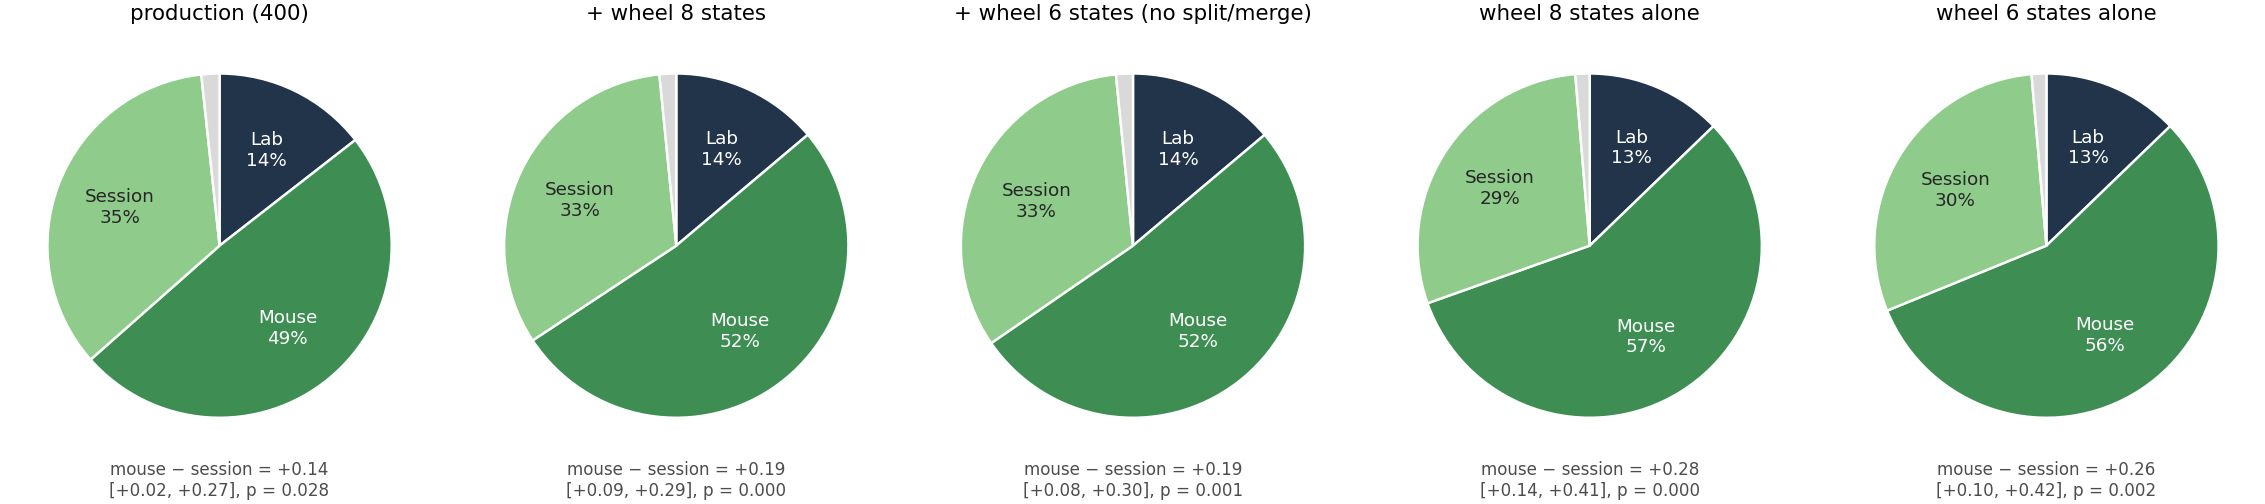

In [3]:
C = svp.COLORS
fig, axs = plt.subplots(1, len(RES), figsize=(2.1 * len(RES), 2.6))
for ax, (name, r) in zip(axs, RES.items()):
    v = np.clip(r['share'], 0, None)
    wedges, _ = ax.pie(v, colors=[C[k] for k in ('Lab', 'Mouse', 'Session', 'Noise')], startangle=90, counterclock=False,
                       wedgeprops=dict(edgecolor='white', linewidth=0.8))
    for w, k, val in zip(wedges, ('Lab', 'Mouse', 'Session', 'Noise'), v):
        if val < 0.05: continue
        a = np.deg2rad((w.theta1 + w.theta2) / 2)
        ax.text(0.62 * np.cos(a), 0.62 * np.sin(a), f'{k}\n{100 * val:.0f}%', ha='center', va='center', fontsize=6,
                color='white' if k in ('Lab', 'Mouse') else '0.15')
    d, lo, hi, p = r['diff']
    ax.set_title(name, fontsize=7)
    ax.text(0, -1.25, f'mouse − session = {d:+.2f}\n[{lo:+.2f}, {hi:+.2f}], p = {p:.3f}', ha='center', va='top', fontsize=5.5, color='0.3')
    ax.set_aspect('equal')
plt.tight_layout(); plt.show()